# Canada's Wildfire Burden: Where It Falls, and Whether the Data Can Be Trusted

Scope: the approved fixed-reporting-agency series, as recorded in data/analysis_scope.json. Counts are reported records, not verified unique incidents. Agency is the reporting dimension, not geographic jurisdiction.

Source: Canadian Forest Service, Natural Resources Canada, Canadian National Fire Database - Agency Fire Data. Contains information licensed under the Open Government Licence - Canada. Source identity and checksum: data/source_versions.csv.

The opening answer is a placeholder and will be written last, after the detail pages are verified. Finding headings remain DRAFT: verify for the reviewer's wording. No Power BI assets are created here. The peak-year reported-area total is pending NFD reconciliation wherever displayed.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.analyse import query
from src.review_analysis import tables
review=tables()
review['decade_sensitivity']=pd.read_csv(ROOT/'data/processed/review_tables/decade_sensitivity.csv')
review['pooling_comparison']=pd.read_csv(ROOT/'data/processed/review_tables/pooling_comparison.csv')
def chart(name): display(Image(filename=str(ROOT/'images'/(name+'.png'))))


## The answer will be written after the detail is verified
I leave the opening synthesis pending. This notebook provides the trust checks used by the concentration and burden story.

## Concentration needs a source-quality check
I interpret the concentration results in the companion notebook alongside the recording patterns below. A precise calculation does not establish uniform measurement practices.

## DRAFT: verify: Recorded sizes cluster at different small values across agencies
I count sizes at exactly zero, one hundredth and one tenth of a hectare by reporting agency. I show separate near-value counts because the source includes legacy numeric approximations; no sizes are rounded or recoded.

,reporting_agency,records,exactly_zero,exactly_001,exactly_01,near_001,near_01,exactly_zero_pct,exactly_001_pct,exactly_01_pct,near_001_pct,near_01_pct
0,AB,35475,0,16231,3844,16231,3844,0.000000,45.753347,10.835800,45.753347,10.835800
1,BC,43677,255,1896,3930,1896,3930,0.583831,4.340957,8.997871,4.340957,8.997871
2,MB,10828,154,0,1809,0,1809,1.422239,0.000000,16.706686,0.000000,16.706686
3,NB,7032,66,0,3440,0,3440,0.938567,0.000000,48.919226,0.000000,48.919226
4,NL,2540,1115,0,361,0,361,43.897638,0.000000,14.212598,0.000000,14.212598
5,NS,5825,929,689,623,838,721,15.948498,11.828326,10.695279,14.386266,12.377682
6,NT,5222,70,295,285,301,301,1.340483,5.649177,5.457679,5.764075,5.764075
7,ON,23662,2,0,490,0,10706,0.008452,0.000000,2.070831,0.000000,45.245541
8,PC,2815,41,448,533,448,533,1.456483,15.914742,18.934281,15.914742,18.934281
9,QC,15636,6159,0,2222,0,2222,39.389870,0.000000,14.210796,0.000000,14.210796


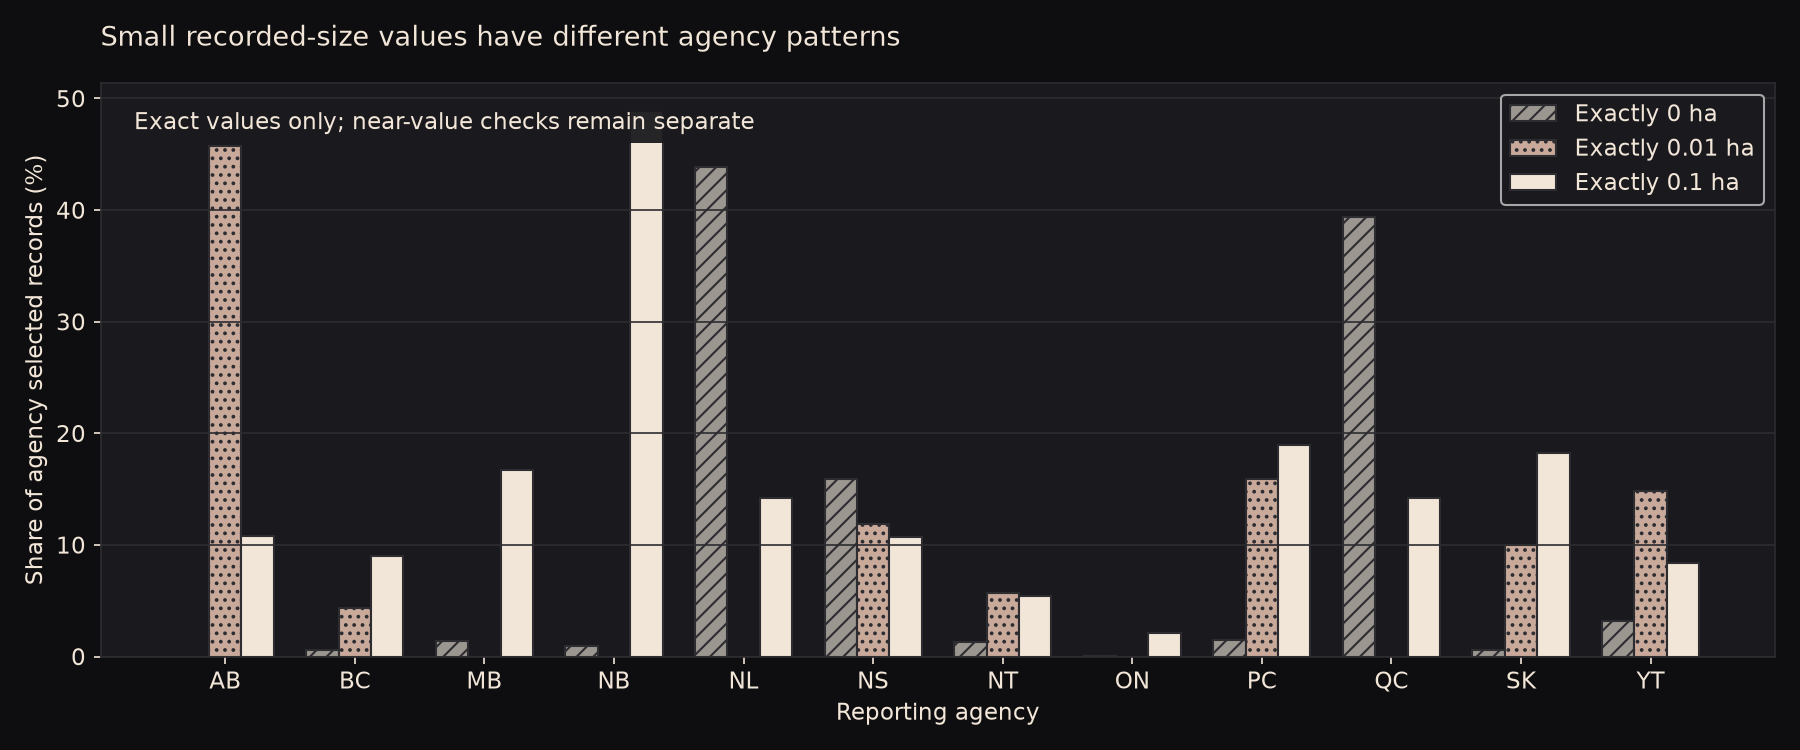

In [2]:
display(review['heaping'])
chart('recording_conventions')


### Takeaway
The near-one-tenth-hectare share is 48.92% for NB and 5.76% for NT. I see different recording patterns across agencies, consistent with different conventions or measurement precision, but I cannot establish each agency's official convention from heaping alone. The strict-equality columns remain distinct from the tolerance diagnostic.

## DRAFT: verify: Zero inclusion changes the selected median
I compare the existing median with a positive-size-only sensitivity while leaving the primary calculation unchanged.

In [3]:
display(query('SELECT COUNT(*) AS records,AVG(CASE WHEN size_ha=0 THEN 1.0 ELSE 0.0 END) AS zero_share FROM vw_analysis'))


,records,zero_share
0,168276,0.053264


In [4]:
sizes=query('SELECT size_ha FROM vw_analysis').size_ha
display(pd.DataFrame({'scope':['Including zeros','Positive sizes only'],'records':[len(sizes),int(sizes.gt(0).sum())],'median_ha':[sizes.median(),sizes[sizes.gt(0)].median()]}))

,scope,records,median_ha
0,Including zeros,168276,0.1
1,Positive sizes only,159313,0.2


### Takeaway
The selected median is 0.10 hectares including zeros and 0.20 hectares excluding them, as the executed table shows. I keep valid zeros in the primary result and show the positive-size result as sensitivity. Zero is not automatically recoded as missing.

## DRAFT: verify: A populated coverage cell does not certify complete reporting
I inspect source counts by agency and year, with missing and outside-coverage states kept explicit.

,reporting_agency,year,source_records,selected_records,coverage_status
0,AB,2000,783,783,Records present; completeness unverified
1,AB,2018,1299,1299,Records present; completeness unverified
2,AB,2025,1338,1338,Records present; completeness unverified
3,BC,2000,1526,1526,Records present; completeness unverified
4,BC,2018,2089,2089,Records present; completeness unverified
5,BC,2025,1372,1372,Records present; completeness unverified
6,MB,2000,353,353,Records present; completeness unverified
7,MB,2018,476,476,Records present; completeness unverified
8,MB,2025,444,444,Records present; completeness unverified
9,NB,2000,333,333,Records present; completeness unverified


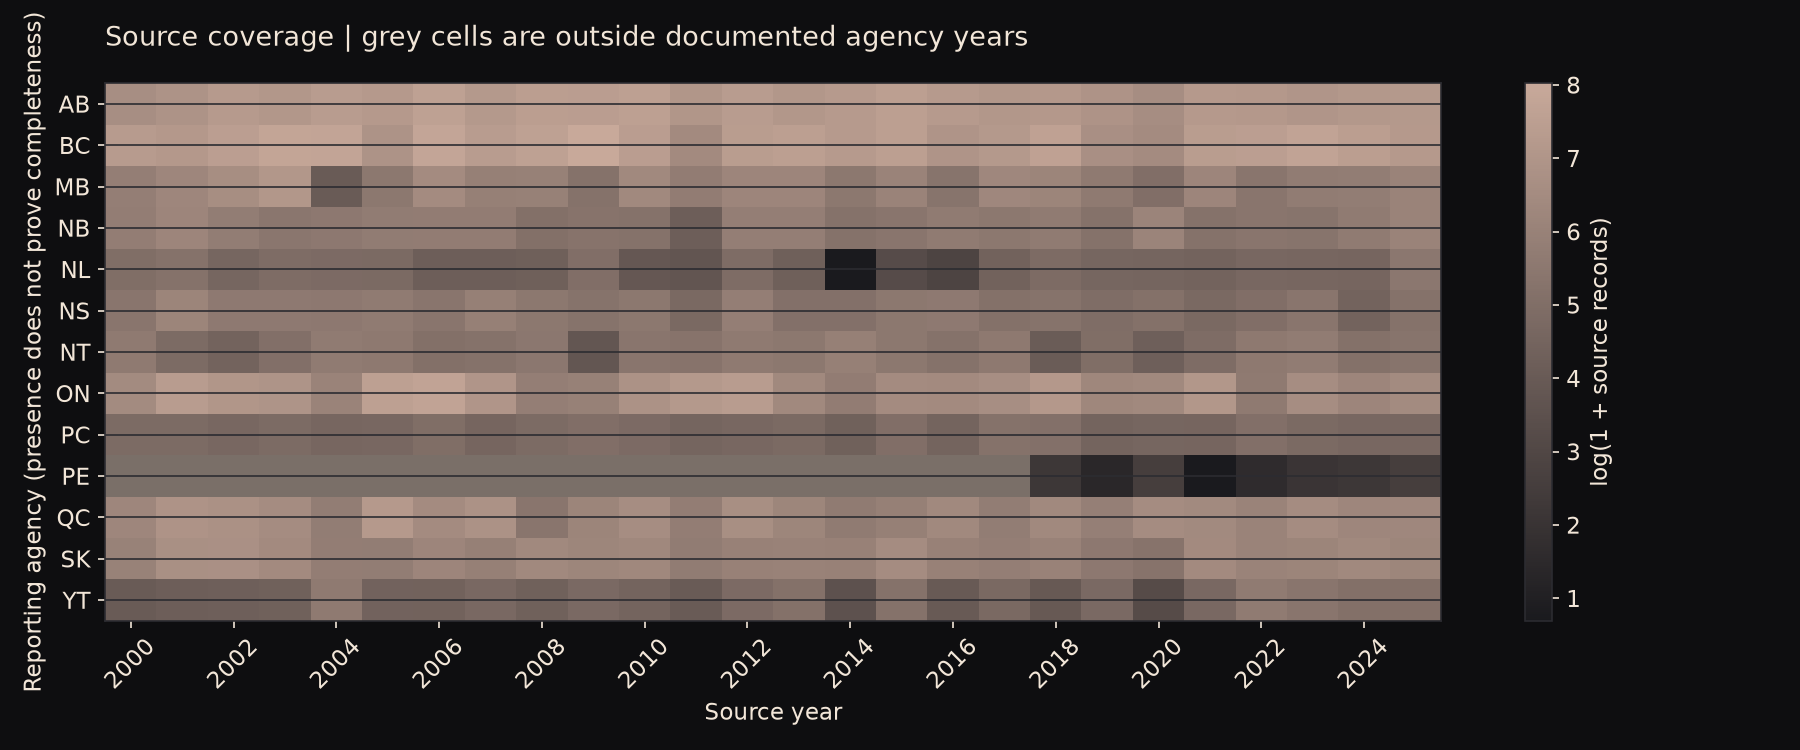

In [5]:
display(query("SELECT reporting_agency,year,source_records,selected_records,coverage_status FROM vw_coverage WHERE year BETWEEN 2000 AND 2025 AND (year IN (2000,2018,2025) OR coverage_status<>'Records present; completeness unverified') ORDER BY reporting_agency,year"))
chart('coverage')


### Takeaway
The matrix shows submissions and documented coverage, not a completeness certificate. PE is displayed for context but remains outside the main fixed-agency series. I would verify an unusually small submission before treating it as low fire activity.

## DRAFT: verify: Missing report dates and unknown causes vary over time
I track these gaps using source-wide denominators before analytical exclusions, separately from selected-cohort shares.

,unknown_cause_share,missing_report_date_share
0,0.046121,0.020312


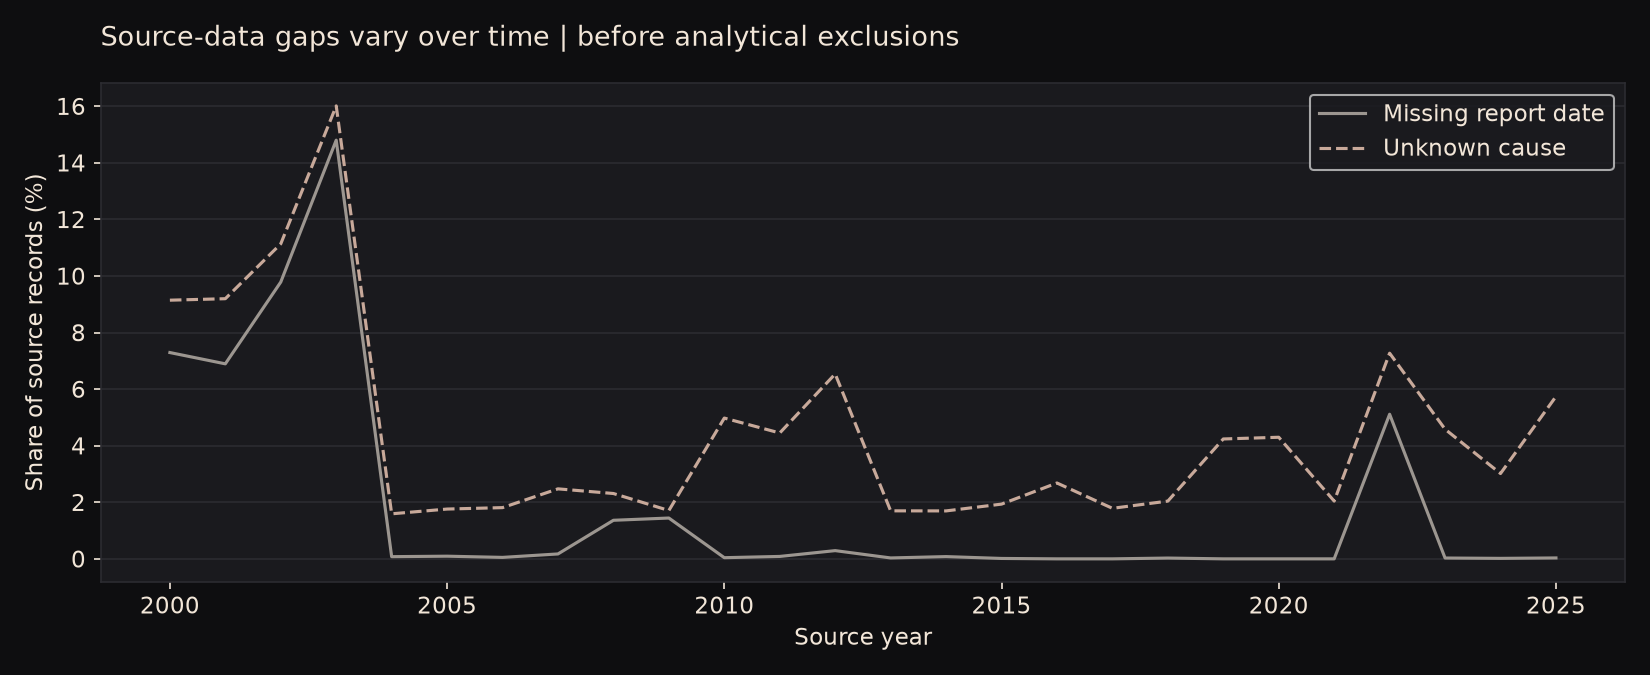

In [6]:
display(query('SELECT unknown_cause_share,missing_report_date_share FROM vw_kpi_summary'))
chart('quality_trends')


### Takeaway
The source-wide chart and selected-cohort table have different denominators, so I do not compare their percentages as if they were identical. Changes in recorded gaps can affect comparisons across time. Independent NFD checks remain pending.

## Date conflicts remain visible and external agreement remains unverified
I retain the supplied values and their flags rather than invent corrected dates.

In [7]:
display(query('SELECT SUM(invalid_calendar_date) AS invalid_calendar_dates,SUM(report_calendar_conflict) AS report_calendar_conflicts,SUM(out_before_report) AS out_before_report FROM fact_fire'))


,invalid_calendar_dates,report_calendar_conflicts,out_before_report
0,4049,638,546


In [8]:
display(query('SELECT COUNT(*) AS verified_nfd_reference_rows FROM fact_nfd_annual'))


,verified_nfd_reference_rows
0,0


### Takeaway
The source includes date conflicts, while the NFD reference table is still empty. Internal reconciliation verifies the calculations, not the source coverage. The 2023 reported-area total is pending NFD reconciliation.